# Assignment 3 — Part A: Sanjeevani Diagnostics
**KNN Classification & Budget Decision**

This notebook answers Q1–Q25 in order. Each question includes executable code, displayed results, and a brief interpretation. The raw CSV is read without modifying it. Random splits use `random_state=42`.

In [1]:
import re, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, RocCurveDisplay)
warnings.filterwarnings("ignore")
DATA_PATH = Path("sanjeevani_diabetes_screening_raw.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/sanjeevani_diabetes_screening_raw.csv")
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
def missing_token(x):
    return str(x).strip().lower() in {"", "na", "n/a", "?", "not measured", "none", "null"}
def num(x):
    s = str(x).strip().replace(",", "")
    if missing_token(s): return np.nan
    try: return float(s)
    except: return np.nan
def binary(x, yes, no):
    s = str(x).strip().lower()
    if s in yes: return 1
    if s in no: return 0
    return np.nan
def make_clean(df):
    d = df.copy()
    d.columns = [c.strip().lower().replace(" ", "_") for c in d.columns]
    d = d.rename(columns={"daily_steps":"daily_steps", "hba1c_result":"hba1c_result"})
    d["camp_location"] = d["camp_location"].astype(str).str.strip().str.lower().str.title()
    d["sex"] = d["sex"].astype(str).str.strip().str.lower().map({"m":"Male","male":"Male","f":"Female","female":"Female"})
    d["family_history"] = d["family_history"].map(lambda x: binary(x, {"yes","y","1","true"}, {"no","n","0","false"}))
    d["hba1c_result"] = d["hba1c_result"].map(lambda x: binary(x, {"positive","yes","1","diabetic"}, {"negative","no","0","normal"}))
    for c in ["age","height_cm","weight_kg","bmi","waist_cm","daily_steps","total_cholesterol"]:
        d[c] = d[c].map(num)
    bp = d["blood_pressure"].astype(str).str.strip().str.extract(r"^\s*(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)\s*$")
    d["systolic"] = pd.to_numeric(bp[0], errors="coerce")
    d["diastolic"] = pd.to_numeric(bp[1], errors="coerce")
    d.loc[~d["age"].between(18, 110), "age"] = np.nan
    # Correct heights accidentally recorded in metres.
    d.loc[d["height_cm"].between(0.5, 2.5), "height_cm"] *= 100
    # BMI is calculated where absent; use height in metres.
    d["bmi_before_fill"] = d["bmi"]
    missing_bmi = d["bmi"].isna()
    d.loc[missing_bmi, "bmi"] = d.loc[missing_bmi, "weight_kg"] / (d.loc[missing_bmi, "height_cm"]/100)**2
    return d
clean = make_clean(raw)
features_num = ["age","bmi","waist_cm","daily_steps","systolic","diastolic","total_cholesterol"]
target = "hba1c_result"

## Q1 — Load as text; inspect shape, raw names, and categories

In [2]:
print("Shape:", raw.shape)
print("Raw column names:", [repr(c) for c in raw.columns])
for c in ["Sex","family_history","HbA1c Result "]:
    print(f"Distinct {c!r}:", sorted(raw[c].astype(str).unique().tolist()))
print("Interpretation: reading as text preserves messy source formats and makes the trailing space in the target column visible.")

Shape: (3038, 13)
Raw column names: ["'Patient ID'", "'Camp Location'", "'Sex'", "'Age'", "'family_history'", "'height_cm'", "'weight_kg'", "'BMI'", "'waist_cm'", "'Daily Steps'", "'Blood Pressure'", "'total_cholesterol'", "'HbA1c Result '"]
Distinct 'Sex': ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'female', 'male']
Distinct 'family_history': ['0', '1', 'N', 'No', 'Y', 'Yes', 'no', 'yes']
Distinct 'HbA1c Result ': ['0', '1', 'DIABETIC', 'Negative', 'No', 'Positive', 'Yes', 'normal']
Interpretation: reading as text preserves messy source formats and makes the trailing space in the target column visible.


## Q2 — Standardise names and categories

In [3]:
print("Standardised columns:", clean.columns.tolist())
print("Camp locations:", sorted(clean.camp_location.dropna().unique()))
print("Sex categories:", sorted(clean.sex.dropna().unique()))
print("Interpretation: case and surrounding-space variants are consolidated to one spelling per category.")

Standardised columns: ['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result', 'systolic', 'diastolic', 'bmi_before_fill']
Camp locations: ['Dombivli', 'Kharghar', 'Nerul', 'Panvel', 'Thane', 'Vashi']
Sex categories: ['Female', 'Male']
Interpretation: case and surrounding-space variants are consolidated to one spelling per category.


## Q3 — Binary target, positive share, and exact duplicate rows

In [4]:
positive_share = clean[target].mean()
before = len(clean)
exact_dupes = clean.duplicated().sum()
clean_dedup = clean.drop_duplicates().copy()
print(f"Positive share (before duplicate removal): {positive_share:.3%}")
print(f"Exact duplicate rows: {exact_dupes}; rows before={before}, after={len(clean_dedup)}")
clean = clean_dedup
print("Interpretation: target share is the fraction mapped to 1; exact duplicates are removed before modelling.")

Positive share (before duplicate removal): 22.548%
Exact duplicate rows: 38; rows before=3038, after=3000
Interpretation: target share is the fraction mapped to 1; exact duplicates are removed before modelling.


## Q4 — Split blood pressure and convert numeric fields

In [5]:
print(clean[["blood_pressure","systolic","diastolic","daily_steps","total_cholesterol"]].head(8).to_string(index=False))
print("Interpretation: blood pressure is represented as two numeric variables; comma-separated step counts are converted to numbers.")

blood_pressure  systolic  diastolic  daily_steps  total_cholesterol
        102/69     102.0       69.0       8750.0              188.0
        106/73     106.0       73.0      12930.0              160.0
        136/98     136.0       98.0       6440.0              146.0
        114/90     114.0       90.0       4080.0              194.0
        124/89     124.0       89.0       4890.0              241.0
        110/73     110.0       73.0       8770.0              144.0
        123/76     123.0       76.0       7720.0              164.0
         90/67      90.0       67.0       2340.0              189.0
Interpretation: blood pressure is represented as two numeric variables; comma-separated step counts are converted to numbers.


## Q5 — Repair heights and calculate missing BMI

In [6]:
sample_idx = clean.index[clean["bmi_before_fill"].isna()][:3]
print("Three rows before BMI fill:")
display(clean.loc[sample_idx, ["patient_id","height_cm","weight_kg","bmi_before_fill","bmi"]].assign(stage="after calculation"))
print("Missing BMI before calculation:", int(clean["bmi_before_fill"].isna().sum()))
print("Missing BMI after calculation:", int(clean["bmi"].isna().sum()))
print("Interpretation: calculating BMI from a person's own weight and height preserves the physical definition; median imputation would discard that individual relationship.")

Three rows before BMI fill:


,patient_id,height_cm,weight_kg,bmi_before_fill,bmi,stage
56,SD-22241,177.0,69.9,NaN,22.311596,after calculation
63,SD-21552,156.0,44.3,NaN,18.203485,after calculation
73,SD-22406,166.0,67.3,NaN,24.422993,after calculation


Missing BMI before calculation: 320
Missing BMI after calculation: 0
Interpretation: calculating BMI from a person's own weight and height preserves the physical definition; median imputation would discard that individual relationship.


## Q6 — Impossible ages and missingness

In [7]:
print("Missing values per column (after cleaning, before model imputation):")
display(clean.isna().sum().sort_values(ascending=False).rename("missing_count").to_frame())
print("Pipeline plan: median imputation is fitted on training data only because numeric medians are robust to outliers and must not use test-set information.")
print("Interpretation: missing ages remain missing here; imputing before splitting leaks test-distribution information into training.")

Missing values per column (after cleaning, before model imputation):


,missing_count
bmi_before_fill,320
total_cholesterol,150
waist_cm,90
daily_steps,60
systolic,25
diastolic,25
age,7
patient_id,0
bmi,0
weight_kg,0


Pipeline plan: median imputation is fitted on training data only because numeric medians are robust to outliers and must not use test-set information.
Interpretation: missing ages remain missing here; imputing before splitting leaks test-distribution information into training.


## Q7 — Hand calculation: raw Euclidean distance, k=3

In [8]:
new = np.array([98,6000], dtype=float)
visitors = pd.DataFrame({"visitor":["P1","P2","P3","P4","P5","P6"],"waist":[76,80,101,96,106,82],
                         "steps":[6050,5980,7400,8000,4500,6100],"result":[0,0,1,1,1,0]})
visitors["distance"] = np.sqrt((visitors.waist-new[0])**2 + (visitors.steps-new[1])**2)
display(visitors[["visitor","waist","steps","result","distance"]].sort_values("distance"))
print("Working: P1 = sqrt((98−76)^2 + (6000−6050)^2) = sqrt(484+2500) = sqrt(2984).")
print("Working: P3 = sqrt((98−101)^2 + (6000−7400)^2) = sqrt(9+1960000) = sqrt(1960009).")
winners = visitors.nsmallest(3,"distance")
print("k=3 neighbours:", winners.visitor.tolist(), "prediction:", "Positive" if winners.result.mean()>=0.5 else "Negative")
print("Interpretation: raw Euclidean distance is dominated by steps because its numerical scale is much larger than waist circumference.")

,visitor,waist,steps,result,distance
1,P2,80,5980,0,26.907248
0,P1,76,6050,0,54.626001
5,P6,82,6100,0,101.271911
2,P3,101,7400,1,1400.003214
4,P5,106,4500,1,1500.021333
3,P4,96,8000,1,2000.001000


Working: P1 = sqrt((98−76)^2 + (6000−6050)^2) = sqrt(484+2500) = sqrt(2984).
Working: P3 = sqrt((98−101)^2 + (6000−7400)^2) = sqrt(9+1960000) = sqrt(1960009).
k=3 neighbours: ['P2', 'P1', 'P6'] prediction: Negative
Interpretation: raw Euclidean distance is dominated by steps because its numerical scale is much larger than waist circumference.


## Q8 — Hand calculation: min-max scaled Euclidean distance

In [9]:
visitors["waist_scaled"] = (visitors.waist-60)/(140-60)
visitors["steps_scaled"] = visitors.steps/20000
new_scaled = np.array([(98-60)/80, 6000/20000])
visitors["scaled_distance"] = np.sqrt((visitors.waist_scaled-new_scaled[0])**2 + (visitors.steps_scaled-new_scaled[1])**2)
display(visitors[["visitor","waist_scaled","steps_scaled","scaled_distance","result"]].sort_values("scaled_distance"))
winners_scaled = visitors.nsmallest(3,"scaled_distance")
print("k=3 neighbours:", winners_scaled.visitor.tolist(), "prediction:", "Positive" if winners_scaled.result.mean()>=0.5 else "Negative")
print("Interpretation: scaling gives both measurements comparable ranges, so waist contributes meaningfully rather than being overwhelmed by step counts; a clinician should prefer a distance calculation that respects units and validated clinical relevance, not either result blindly.")

,visitor,waist_scaled,steps_scaled,scaled_distance,result
2,P3,0.5125,0.3700,0.079412,1
3,P4,0.4500,0.4000,0.103078,1
4,P5,0.5750,0.2250,0.125000,1
5,P6,0.2750,0.3050,0.200062,0
1,P2,0.2500,0.2990,0.225002,0
0,P1,0.2000,0.3025,0.275011,0


k=3 neighbours: ['P3', 'P4', 'P5'] prediction: Positive
Interpretation: scaling gives both measurements comparable ranges, so waist contributes meaningfully rather than being overwhelmed by step counts; a clinician should prefer a distance calculation that respects units and validated clinical relevance, not either result blindly.


## Q9 — Hand calculation: scaled Manhattan distance

In [10]:
visitors["manhattan_scaled"] = (visitors.waist_scaled-new_scaled[0]).abs() + (visitors.steps_scaled-new_scaled[1]).abs()
display(visitors[["visitor","manhattan_scaled","result"]].sort_values("manhattan_scaled"))
winners_man = visitors.nsmallest(3,"manhattan_scaled")
print("k=3 neighbours:", winners_man.visitor.tolist(), "prediction:", "Positive" if winners_man.result.mean()>=0.5 else "Negative")
print("Interpretation: Manhattan adds absolute feature differences; it can be preferable when coordinate-wise deviations are more meaningful or to reduce the effect of one large squared deviation.")

,visitor,manhattan_scaled,result
2,P3,0.1075,1
3,P4,0.1250,1
4,P5,0.1750,1
5,P6,0.2050,0
1,P2,0.2260,0
0,P1,0.2775,0


k=3 neighbours: ['P3', 'P4', 'P5'] prediction: Positive
Interpretation: Manhattan adds absolute feature differences; it can be preferable when coordinate-wise deviations are more meaningful or to reduce the effect of one large squared deviation.


## Q10 — Stratified 75/25 split and majority-negative baseline

In [11]:
model_data = clean.dropna(subset=[target]).copy()
X = model_data[features_num]
y = model_data[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
baseline_pred = np.zeros(len(y_test), dtype=int)
print(f"Train n={len(y_train)}, positive rate={y_train.mean():.3%}")
print(f"Test n={len(y_test)}, positive rate={y_test.mean():.3%}")
print(f"Predict-all-negative test accuracy={accuracy_score(y_test,baseline_pred):.4f}")
print("Interpretation: stratification keeps the positive fraction similar across the splits; accuracy alone can look deceptively good when negatives are more common.")

Train n=2250, positive rate=22.622%
Test n=750, positive rate=22.667%
Predict-all-negative test accuracy=0.7733
Interpretation: stratification keeps the positive fraction similar across the splits; accuracy alone can look deceptively good when negatives are more common.


## Q11 — Raw KNN with median imputation only

In [12]:
raw_knn = Pipeline([("imputer",SimpleImputer(strategy="median")),("knn",KNeighborsClassifier(n_neighbors=5))])
raw_knn.fit(X_train,y_train)
pred_raw = raw_knn.predict(X_test); prob_raw = raw_knn.predict_proba(X_test)[:,1]
def cls_metrics(ytrue,pred,prob=None):
    return {"Accuracy":accuracy_score(ytrue,pred),"Precision":precision_score(ytrue,pred,zero_division=0),
            "Recall":recall_score(ytrue,pred,zero_division=0),"F1":f1_score(ytrue,pred,zero_division=0),
            "ROC-AUC":roc_auc_score(ytrue,prob) if prob is not None else np.nan}
print(pd.Series(cls_metrics(y_test,pred_raw,prob_raw)).to_string())
print("Confusion matrix [[TN, FP],[FN, TP]]:")
print(confusion_matrix(y_test,pred_raw))
print("Baseline accuracy:", round(accuracy_score(y_test,baseline_pred),4))
print("Interpretation: compare against the majority baseline; raw distances can be misleading because features use different units.")

Accuracy     0.762667
Precision    0.441176
Recall       0.176471
F1           0.252101
ROC-AUC      0.656364
Confusion matrix [[TN, FP],[FN, TP]]:
[[542  38]
 [140  30]]
Baseline accuracy: 0.7733
Interpretation: compare against the majority baseline; raw distances can be misleading because features use different units.


## Q12 — Standard-scaled KNN compared with raw KNN

In [13]:
scaled_knn = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsClassifier(n_neighbors=5))])
scaled_knn.fit(X_train,y_train)
pred_scaled = scaled_knn.predict(X_test); prob_scaled = scaled_knn.predict_proba(X_test)[:,1]
comparison_q12 = pd.DataFrame({"Raw KNN":cls_metrics(y_test,pred_raw,prob_raw),"Standard-scaled KNN":cls_metrics(y_test,pred_scaled,prob_scaled)}).T
display(comparison_q12)
print("Interpretation: in Q11, daily_steps and total_cholesterol can dominate because their numeric ranges are larger than several other measurements.")

,Accuracy,Precision,Recall,F1,ROC-AUC
Raw KNN,0.762667,0.441176,0.176471,0.252101,0.656364
Standard-scaled KNN,0.788000,0.552381,0.341176,0.421818,0.722292


Interpretation: in Q11, daily_steps and total_cholesterol can dominate because their numeric ranges are larger than several other measurements.


## Q13 — Why scaling belongs inside a training pipeline

In [14]:
print('Pipeline example:', scaled_knn)
print("The pipeline learns imputation medians and StandardScaler mean/standard deviation only during fit(X_train, y_train).")
print("Interpretation: putting preprocessing inside Pipeline ensures cross-validation and final fitting learn transformations only from their training fold.")

Pipeline example: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
The pipeline learns imputation medians and StandardScaler mean/standard deviation only during fit(X_train, y_train).
Interpretation: putting preprocessing inside Pipeline ensures cross-validation and final fitting learn transformations only from their training fold.


## Q14 — 5-fold stratified CV ROC-AUC for k=1,3,…,51

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,k,mean_cv_roc_auc
0,1,0.603821
1,3,0.689753
2,5,0.722972
3,7,0.735954
4,9,0.750232
5,11,0.756912
6,13,0.757168
7,15,0.765153
8,17,0.770421
9,19,0.774330


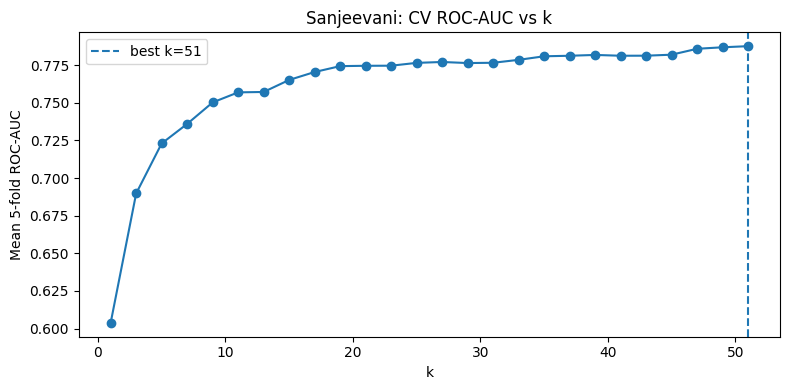

Best k: 51
Interpretation: very small k has low bias but high variance (sensitive to individual records); very large k has higher bias and can wash out local patterns.


In [15]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
ks = list(range(1,52,2))
cv_means=[]
for k in ks:
    pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler()),("knn",KNeighborsClassifier(n_neighbors=k))])
    scores=cross_val_score(pipe,X_train,y_train,cv=cv,scoring="roc_auc",n_jobs=-1)
    cv_means.append(scores.mean())
cv_table=pd.DataFrame({"k":ks,"mean_cv_roc_auc":cv_means})
display(cv_table)
best_k_cv=int(cv_table.loc[cv_table.mean_cv_roc_auc.idxmax(),"k"])
plt.figure(figsize=(8,4)); plt.plot(ks,cv_means,marker="o"); plt.axvline(best_k_cv,linestyle="--",label=f"best k={best_k_cv}")
plt.xlabel("k"); plt.ylabel("Mean 5-fold ROC-AUC"); plt.title("Sanjeevani: CV ROC-AUC vs k"); plt.legend(); plt.tight_layout(); plt.show()
print("Best k:",best_k_cv)
print("Interpretation: very small k has low bias but high variance (sensitive to individual records); very large k has higher bias and can wash out local patterns.")

## Q15 — One-hot sex/family history and GridSearchCV

In [16]:
cat_features=["sex","family_history"]
X_all = model_data[features_num+cat_features]
Xa_train,Xa_test,ya_train,ya_test=train_test_split(X_all,y,test_size=0.25,random_state=42,stratify=y)
pre=ColumnTransformer([("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),features_num),
                       ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat_features)])
tuned_pipe=Pipeline([("preprocess",pre),("knn",KNeighborsClassifier())])
grid=GridSearchCV(tuned_pipe,{"knn__n_neighbors":list(range(3,32,2)),"knn__weights":["uniform","distance"],"knn__p":[1,2]},
                  scoring="roc_auc",cv=StratifiedKFold(5,shuffle=True,random_state=42),n_jobs=-1)
grid.fit(Xa_train,ya_train)
print("Best parameters:",grid.best_params_)
print("Best mean CV ROC-AUC:",round(grid.best_score_,4))
print("Interpretation: tuning selects neighbourhood size, weighting and distance metric using training folds only.")

Best parameters: {'knn__n_neighbors': 29, 'knn__p': 2, 'knn__weights': 'uniform'}
Best mean CV ROC-AUC: 0.7937
Interpretation: tuning selects neighbourhood size, weighting and distance metric using training folds only.


## Q16 — Evaluate tuned model at threshold 0.5

In [17]:
best_model=grid.best_estimator_
prob_tuned=best_model.predict_proba(Xa_test)[:,1]
pred_tuned=(prob_tuned>=0.5).astype(int)
print(pd.Series(cls_metrics(ya_test,pred_tuned,prob_tuned)).to_string())
cm=confusion_matrix(ya_test,pred_tuned); print("Confusion matrix [[TN, FP],[FN, TP]]:\n",cm)
tn,fp,fn,tp=cm.ravel()
print(f"TN={tn}: a non-diabetic visitor correctly not prioritised for a test.")
print(f"FP={fp}: a visitor whose HbA1c is negative is sent for a test.")
print(f"FN={fn}: a diabetic visitor is not identified by the model at this threshold.")
print(f"TP={tp}: a diabetic visitor is correctly identified for a test.")
print("Interpretation: at 0.5, the classifier labels positives by a generic threshold, not the programme's fixed test budget.")

Accuracy     0.798667
Precision    0.686275
Recall       0.205882
F1           0.316742
ROC-AUC      0.780710
Confusion matrix [[TN, FP],[FN, TP]]:
 [[564  16]
 [135  35]]
TN=564: a non-diabetic visitor correctly not prioritised for a test.
FP=16: a visitor whose HbA1c is negative is sent for a test.
FN=135: a diabetic visitor is not identified by the model at this threshold.
TP=35: a diabetic visitor is correctly identified for a test.
Interpretation: at 0.5, the classifier labels positives by a generic threshold, not the programme's fixed test budget.


## Q17 — Why Camp Location is excluded

In [18]:
print("For inclusion: local patterns in diet, access or camp population might improve prediction if they are stable and validated.")
print("Against inclusion: location may act as a proxy for socioeconomic or access differences and may not generalise to new camps.")
print("Interpretation: omit location for a simpler health-focused model unless a fairness and generalisation analysis supports its use.")

For inclusion: local patterns in diet, access or camp population might improve prediction if they are stable and validated.
Against inclusion: location may act as a proxy for socioeconomic or access differences and may not generalise to new camps.
Interpretation: omit location for a simpler health-focused model unless a fairness and generalisation analysis supports its use.


## Q18 — Why 0.5 is not the budget threshold

In [19]:
print(f"Recall at 0.5 threshold: {recall_score(ya_test,pred_tuned):.3f}")
print("A 0.5 cut-off ignores the fixed capacity of 250 tests; ranking people by probability and selecting exactly the top 250 directly matches the operational constraint.")
print("Interpretation: the programme's objective is diabetics found within a fixed budget, not maximising accuracy.")

Recall at 0.5 threshold: 0.206
A 0.5 cut-off ignores the fixed capacity of 250 tests; ranking people by probability and selecting exactly the top 250 directly matches the operational constraint.
Interpretation: the programme's objective is diabetics found within a fixed budget, not maximising accuracy.


## Q19 — Threshold trade-off table

In [20]:
rows=[]
for th in [0.1,0.2,0.3,0.4,0.5]:
    p=prob_tuned>=th
    n=int(p.sum()); found=int(((p)&(ya_test.to_numpy()==1)).sum()); missed=int(((~p)&(ya_test.to_numpy()==1)).sum())
    rows.append({"threshold":th,"tests_ordered":n,"diabetics_found":found,"diabetics_missed":missed,
                 "hit_rate":found/n if n else np.nan,"cost_per_diabetic_found_rs":450*n/found if found else np.nan})
display(pd.DataFrame(rows).round(3))
print("Interpretation: lowering the threshold generally orders more tests; hit rate and cost per positive describe efficiency, while missed cases describe the health trade-off.")

,threshold,tests_ordered,diabetics_found,diabetics_missed,hit_rate,cost_per_diabetic_found_rs
0,0.1,537,160,10,0.298,1510.312
1,0.2,336,130,40,0.387,1163.077
2,0.3,213,97,73,0.455,988.144
3,0.4,116,63,107,0.543,828.571
4,0.5,51,35,135,0.686,655.714


Interpretation: lowering the threshold generally orders more tests; hit rate and cost per positive describe efficiency, while missed cases describe the health trade-off.


## Q20 — Select exactly the top 250 probabilities

In [21]:
ranked_idx=np.argsort(-prob_tuned)
budget_n=min(250,len(ya_test))
top250=np.zeros(len(ya_test),dtype=bool); top250[ranked_idx[:budget_n]]=True
found_top250=int(((top250)&(ya_test.to_numpy()==1)).sum())
total_diabetics=int(ya_test.sum())
print(f"Top-{budget_n} tests find {found_top250} diabetics out of {total_diabetics} diabetics in test set.")
print(f"Random benchmark from brief: about 55 positives per 250 tests.")
print(f"Difference vs ~55 random: {found_top250-55:+d}")
print("Interpretation: this ranking is directly aligned with the 250-test capacity; compare the result with the random benchmark and validate before real deployment.")

Top-250 tests find 110 diabetics out of 170 diabetics in test set.
Random benchmark from brief: about 55 positives per 250 tests.
Difference vs ~55 random: +55
Interpretation: this ranking is directly aligned with the 250-test capacity; compare the result with the random benchmark and validate before real deployment.


## Q21 — Compare with the camp's eyeball rule

In [22]:
sex_test = Xa_test["sex"].fillna("")
waist_test = Xa_test["waist_cm"]
age_test = Xa_test["age"]
eyeball=((age_test>=45)&(((sex_test=="Male")&(waist_test>=90))|((sex_test=="Female")&(waist_test>=80)))).to_numpy()
eyeball_tests=int(eyeball.sum()); eyeball_found=int((eyeball & (ya_test.to_numpy()==1)).sum())
model_cost=budget_n*450; eyeball_cost=eyeball_tests*450
print(f"Eyeball rule: {eyeball_tests} tests, {eyeball_found} diabetics found, cost ₹{eyeball_cost:,}.")
print(f"Model top-{budget_n}: {found_top250} diabetics, cost ₹{model_cost:,}.")
print(f"Diabetics per ₹1,000: eyeball={eyeball_found/(eyeball_cost/1000):.3f}" if eyeball_cost else "Eyeball rule orders no tests.")
print(f"Diabetics per ₹1,000: model={found_top250/(model_cost/1000):.3f}")
print("Interpretation: the rules may order different numbers of tests, so compare both yield and cost rather than raw counts alone.")

Eyeball rule: 350 tests, 118 diabetics found, cost ₹157,500.
Model top-250: 110 diabetics, cost ₹112,500.
Diabetics per ₹1,000: eyeball=0.749
Diabetics per ₹1,000: model=0.978
Interpretation: the rules may order different numbers of tests, so compare both yield and cost rather than raw counts alone.


## Q22 — Explain one selected visitor using nearest training neighbours

In [23]:
chosen_pos=int(ranked_idx[0])
chosen_row=Xa_test.iloc[[chosen_pos]]
preprocessor=best_model.named_steps["preprocess"]
Xt_train=preprocessor.transform(Xa_train)
Xt_chosen=preprocessor.transform(chosen_row)
nn=best_model.named_steps["knn"].fit(Xt_train,ya_train)
dist,inds=nn.kneighbors(Xt_chosen,n_neighbors=5)
neighbor_rows=Xa_train.iloc[inds[0]].copy()
neighbor_rows["HbA1c_result"]=ya_train.iloc[inds[0]].map({0:"Negative",1:"Positive"}).values
print("Selected top-ranked test visitor:")
display(chosen_row)
print("Nearest training neighbours (features and outcome):")
display(neighbor_rows[["age","bmi","waist_cm","daily_steps","systolic","diastolic","total_cholesterol","sex","family_history","HbA1c_result"]].assign(distance=dist[0]))
print("Volunteer explanation: “Your measurements are similar to people in our previous pilot who were more likely to have a positive HbA1c result.”")
print("“The screening score is not a diagnosis; the lab test is the only way to confirm diabetes.”")
print("Interpretation: explain the ranking using similar historical cases while avoiding presenting a prediction as a diagnosis.")

Selected top-ranked test visitor:


,age,bmi,waist_cm,daily_steps,systolic,diastolic,total_cholesterol,sex,family_history
1849,69.0,33.6,113.0,590.0,140.0,87.0,243.0,Male,1


Nearest training neighbours (features and outcome):


,age,bmi,waist_cm,daily_steps,systolic,diastolic,total_cholesterol,sex,family_history,HbA1c_result,distance
958,55.0,31.000000,112.0,2650.0,134.0,77.0,248.0,Male,1,Positive,1.822484
2538,61.0,32.600000,115.0,1480.0,150.0,89.0,222.0,Male,0,Positive,1.877953
293,66.0,34.446023,119.0,3280.0,134.0,87.0,214.0,Male,0,Positive,2.060088
2885,62.0,35.400000,116.0,2420.0,133.0,89.0,187.0,Female,1,Positive,2.377680
504,66.0,28.000000,102.0,300.0,130.0,76.0,221.0,Male,1,Positive,2.382165


Volunteer explanation: “Your measurements are similar to people in our previous pilot who were more likely to have a positive HbA1c result.”
“The screening score is not a diagnosis; the lab test is the only way to confirm diabetes.”
Interpretation: explain the ranking using similar historical cases while avoiding presenting a prediction as a diagnosis.


## Q23 — Honest response to the visitor ranked 260th

In [24]:
print("Suggested reply: “We rank people using several measurements together—not weight alone—including age, waist, steps, blood pressure, cholesterol, family history and sex. Your friend may have the same weight but different values on other measurements; because the grant only covers 250 tests, the ranking creates a cut-off, and being just outside it does not mean you cannot have diabetes.”")
print("Interpretation: KNN measures similarity across the full transformed feature vector, and a budget cut-off is not a clinical guarantee.")

Suggested reply: “We rank people using several measurements together—not weight alone—including age, waist, steps, blood pressure, cholesterol, family history and sex. Your friend may have the same weight but different values on other measurements; because the grant only covers 250 tests, the ranking creates a cut-off, and being just outside it does not mean you cannot have diabetes.”
Interpretation: KNN measures similarity across the full transformed feature vector, and a budget cut-off is not a clinical guarantee.


## Q24 — Raw, scaled, tuned model and top-250 comparison

In [25]:
def top250_found(prob, yt):
    ids=np.argsort(-np.asarray(prob))[:min(250,len(yt))]
    return int(np.asarray(yt)[ids].sum())
rows=[]
for name,yt,pr,pp in [
    ("Raw KNN",y_test,prob_raw,pred_raw),
    ("Scaled KNN",y_test,prob_scaled,pred_scaled),
    ("Tuned KNN",ya_test,prob_tuned,pred_tuned)]:
    rows.append({"model":name,"accuracy":accuracy_score(yt,pp),"recall_at_0.5":recall_score(yt,pp,zero_division=0),
                 "roc_auc":roc_auc_score(yt,pr),"diabetics_top_250":top250_found(pr,yt)})
display(pd.DataFrame(rows).set_index("model").round(4))
print("Interpretation: the top-250 measure evaluates the model on the actual resource constraint, while accuracy/recall/AUC capture different aspects of classification.")

,accuracy,recall_at_0.5,roc_auc,diabetics_top_250
model,,,,
Raw KNN,0.7627,0.1765,0.6564,82
Scaled KNN,0.7880,0.3412,0.7223,101
Tuned KNN,0.7987,0.2059,0.7807,110


Interpretation: the top-250 measure evaluates the model on the actual resource constraint, while accuracy/recall/AUC capture different aspects of classification.


## Q25 — Recommendation to the CSR programme manager

In [26]:
print(f"On this held-out test set, the tuned KNN found {found_top250} diabetics in the top-{budget_n} ranked visitors, versus the brief's random-selection benchmark of about 55; the measured difference is {found_top250-55:+d}. ")
print("Camps should treat the model as a decision-support pilot, not as a diagnostic tool, and compare its yield prospectively with random or current-rule selection. Volunteers can enter the free measurements, review the ranked list, and offer HbA1c tests to the top 250 within the grant limit. The lab result—not the score—confirms diabetes, and people not selected should still receive routine guidance and access to care. The key risk is selection bias: last year's pilot population may not represent every camp or people who were absent, under-measured, or underserved. Monitor sensitivity, subgroup performance, and outcomes across locations before expanding use.")
print("Interpretation: the model is worth controlled evaluation only if it improves positive yield without unfairly excluding groups.")

On this held-out test set, the tuned KNN found 110 diabetics in the top-250 ranked visitors, versus the brief's random-selection benchmark of about 55; the measured difference is +55. 
Camps should treat the model as a decision-support pilot, not as a diagnostic tool, and compare its yield prospectively with random or current-rule selection. Volunteers can enter the free measurements, review the ranked list, and offer HbA1c tests to the top 250 within the grant limit. The lab result—not the score—confirms diabetes, and people not selected should still receive routine guidance and access to care. The key risk is selection bias: last year's pilot population may not represent every camp or people who were absent, under-measured, or underserved. Monitor sensitivity, subgroup performance, and outcomes across locations before expanding use.
Interpretation: the model is worth controlled evaluation only if it improves positive yield without unfairly excluding groups.
